In [78]:
import pandas as pd
import numpy as np
import seaborn as sns                       #visualisation
import matplotlib.pyplot as plt             #visualisation

from generate_data import generate_balanced_data

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve 

from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

import joblib



In [84]:
df_stations = pd.read_csv("station_day.csv")
stations = pd.read_csv("stations.csv")

df = df_stations.merge(
    stations[["StationId", "City", "State", "StationName"]],
    on="StationId",
    how="left",
    validate="many_to_one"
)   

print("Размер до объединения:", df_stations.shape)
print("Размер после объединения:", df.shape)
print("Строк без города:", df["City"].isna().sum())

df.head(5)

Размер до объединения: (108035, 16)
Размер после объединения: (108035, 19)
Строк без города: 0


,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,City,State,StationName
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"


In [8]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,86410.000000,65329.000000,90929.000000,91488.000000,92535.000000,59930.000000,95037.000000,82831.000000,82467.000000,76580.000000,69333.000000,22898.000000,87025.000000
mean,80.272571,157.968427,23.123424,35.240760,41.195055,28.732875,1.605749,12.257634,38.134836,3.358029,15.345394,2.423446,179.749290
std,76.526403,123.418672,34.491019,29.510827,45.145976,24.897797,4.369578,12.984723,39.128004,11.156234,29.348587,6.472409,131.324339
min,0.020000,0.010000,0.010000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,8.000000
25%,31.880000,70.150000,4.840000,15.090000,13.970000,11.900000,0.530000,5.040000,18.895000,0.160000,0.690000,0.000000,86.000000
50%,55.950000,122.090000,10.290000,27.210000,26.660000,23.590000,0.910000,8.950000,30.840000,1.210000,4.330000,0.400000,132.000000
75%,99.920000,208.670000,24.980000,46.930000,50.500000,38.137500,1.450000,14.920000,47.140000,3.610000,17.510000,2.110000,254.000000
max,1000.000000,1000.000000,470.000000,448.050000,467.630000,418.900000,175.810000,195.650000,963.000000,455.030000,454.850000,170.370000,2049.000000


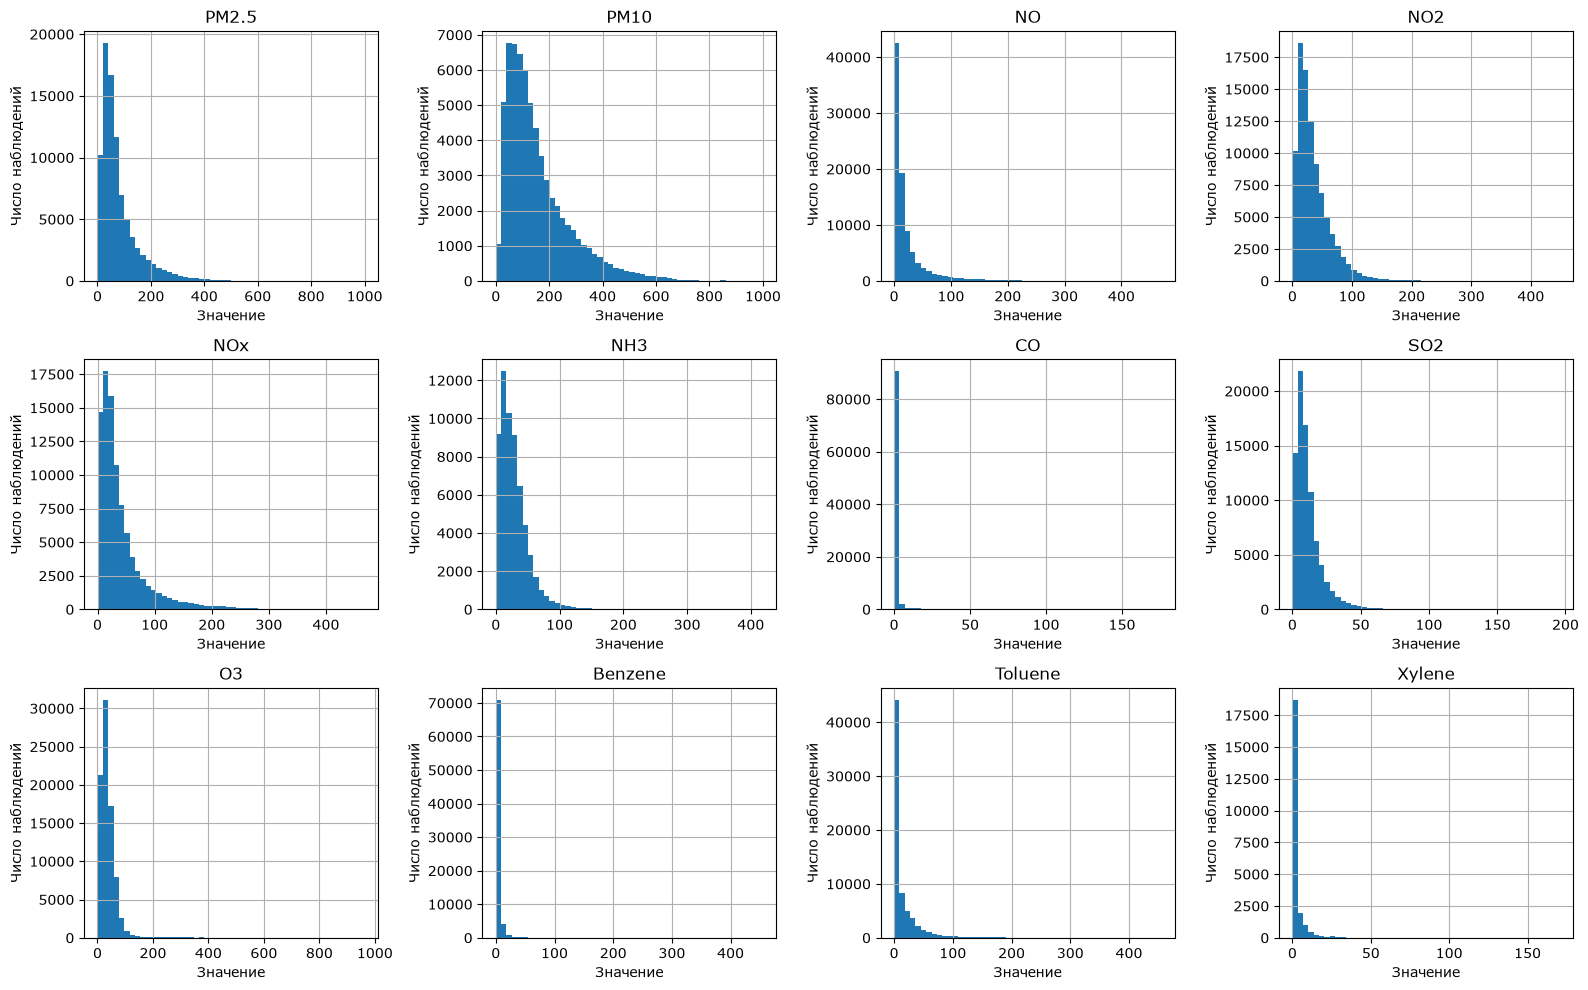

In [9]:
features = [
    "PM2.5", "PM10", "NO", "NO2",
    "NOx", "NH3", "CO", "SO2",
    "O3", "Benzene", "Toluene", "Xylene"
]

axes = df[features].hist(
    bins=50,
    layout=(3, 4),
    figsize=(16, 10)
)

for ax in axes.flat:
    ax.set_xlabel("Значение")
    ax.set_ylabel("Число наблюдений")

plt.tight_layout()
plt.show()

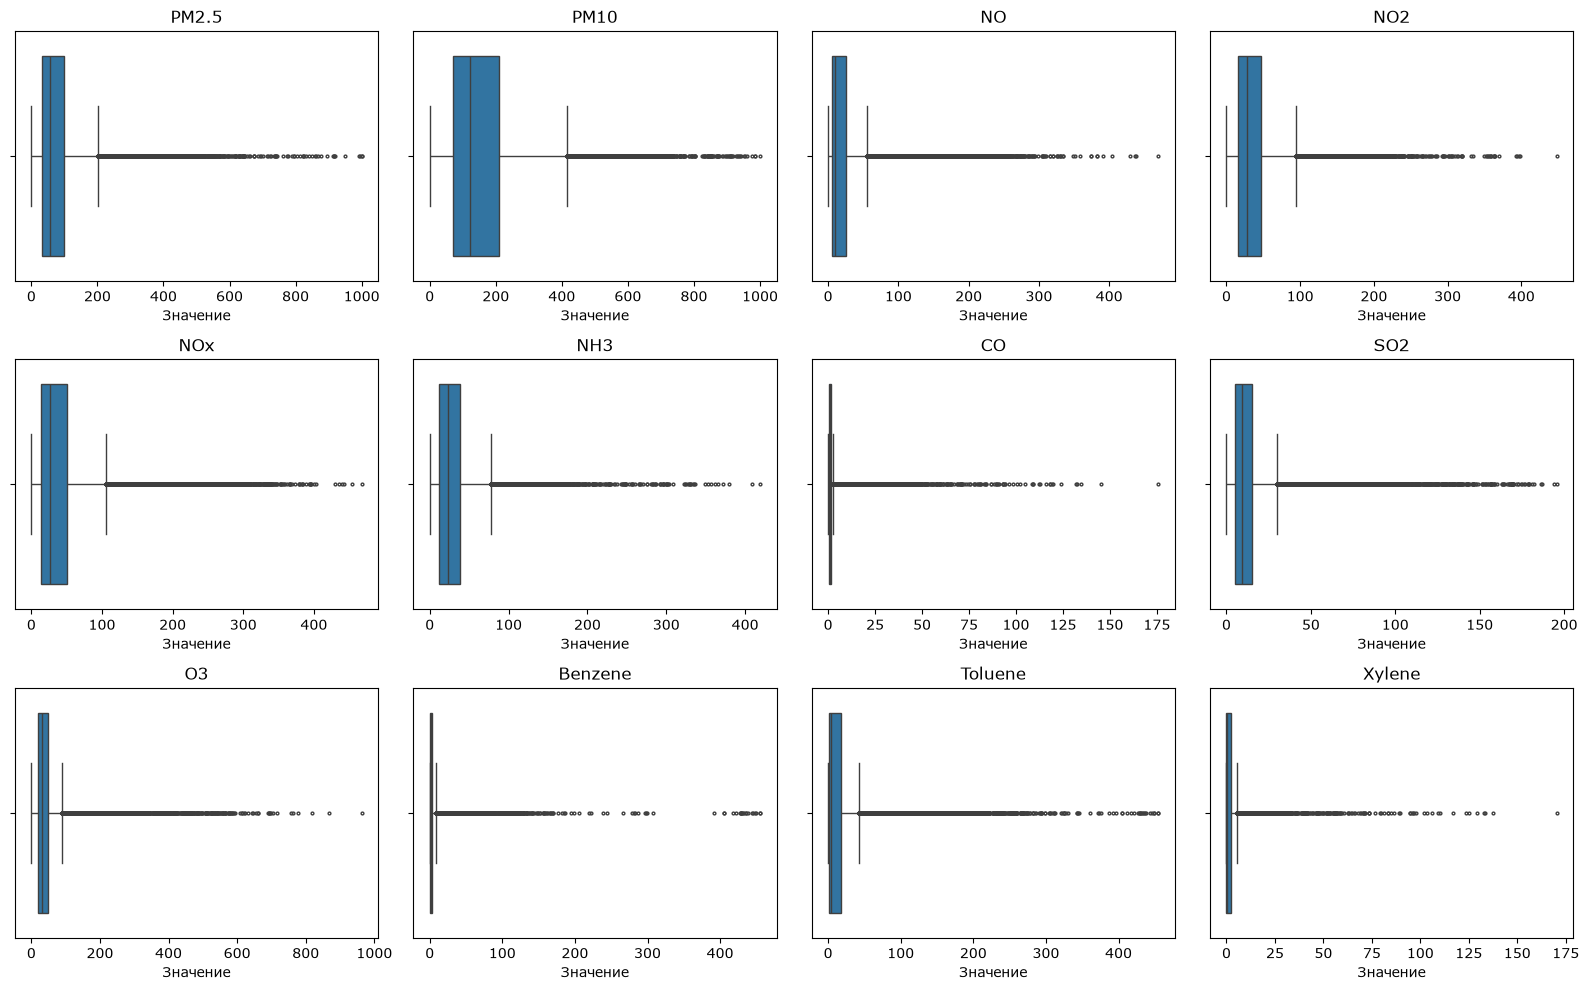

In [10]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(16, 10)
)

for feature, ax in zip(features, axes.flat):
    sns.boxplot(
        data=df,
        x=feature,
        ax=ax,
        fliersize=2
    )

    ax.set_title(feature)
    ax.set_xlabel("Значение")

plt.tight_layout()
plt.show()

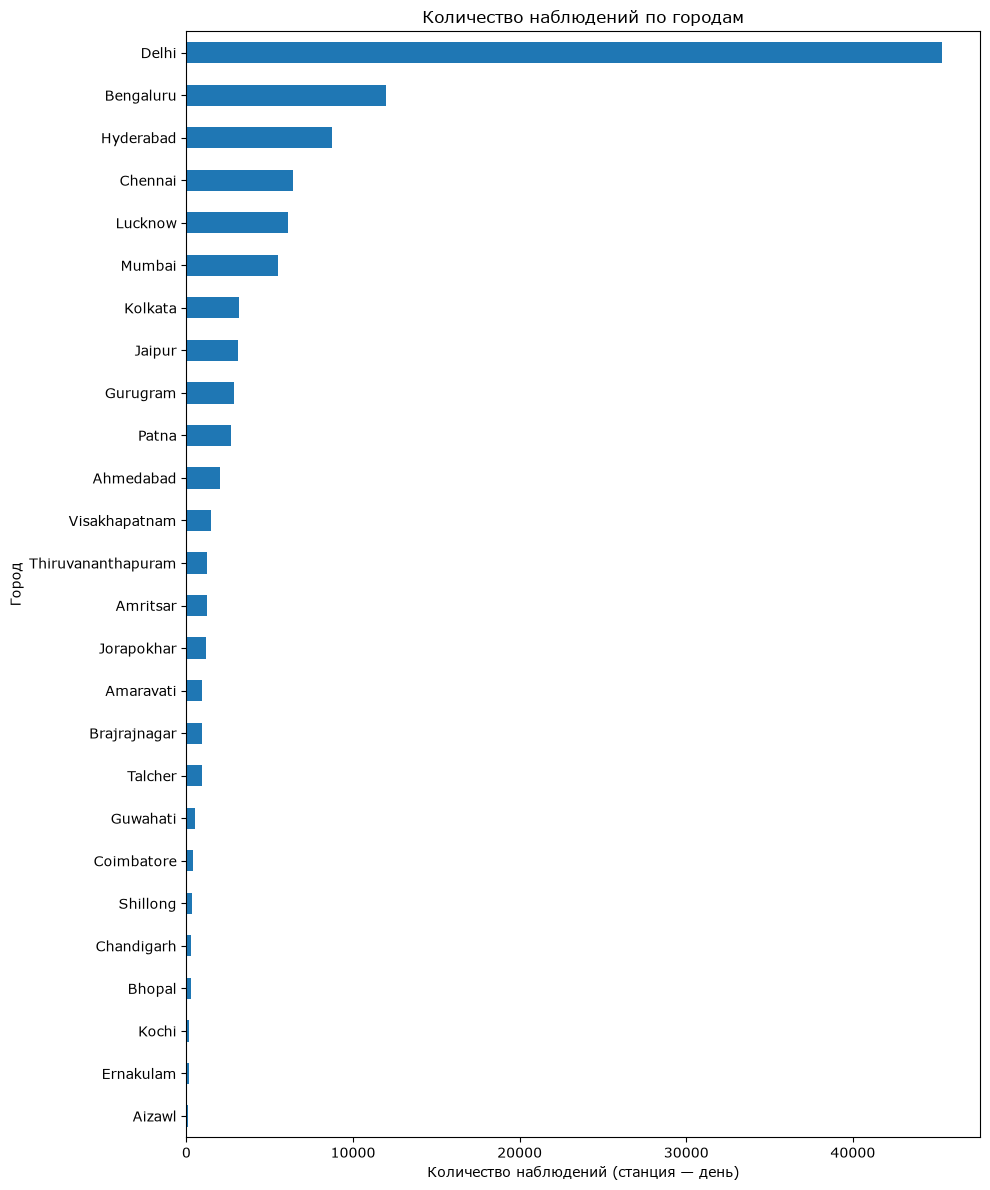

In [11]:
city_counts = (
    df["City"]
    .value_counts()
    .sort_values()
)

city_counts.plot(
    kind="barh",
    figsize=(10, 12)
)

plt.title("Количество наблюдений по городам")
plt.xlabel("Количество наблюдений (станция — день)")
plt.ylabel("Город")

plt.tight_layout()
plt.show()

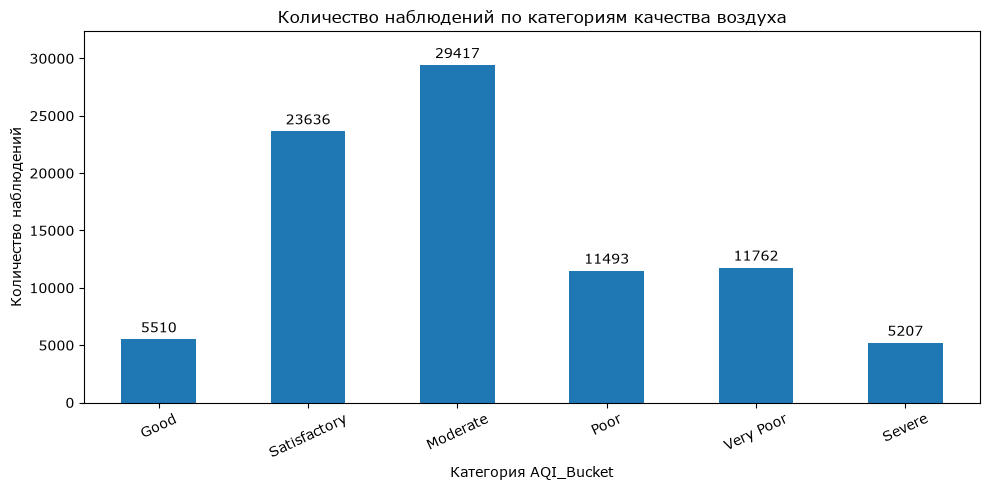

In [12]:
class_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

class_counts = (
    df["AQI_Bucket"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

ax = class_counts.plot(
    kind="bar",
    figsize=(10, 5),
    rot=25
)

ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.1)

plt.title("Количество наблюдений по категориям качества воздуха")
plt.xlabel("Категория AQI_Bucket")
plt.ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()


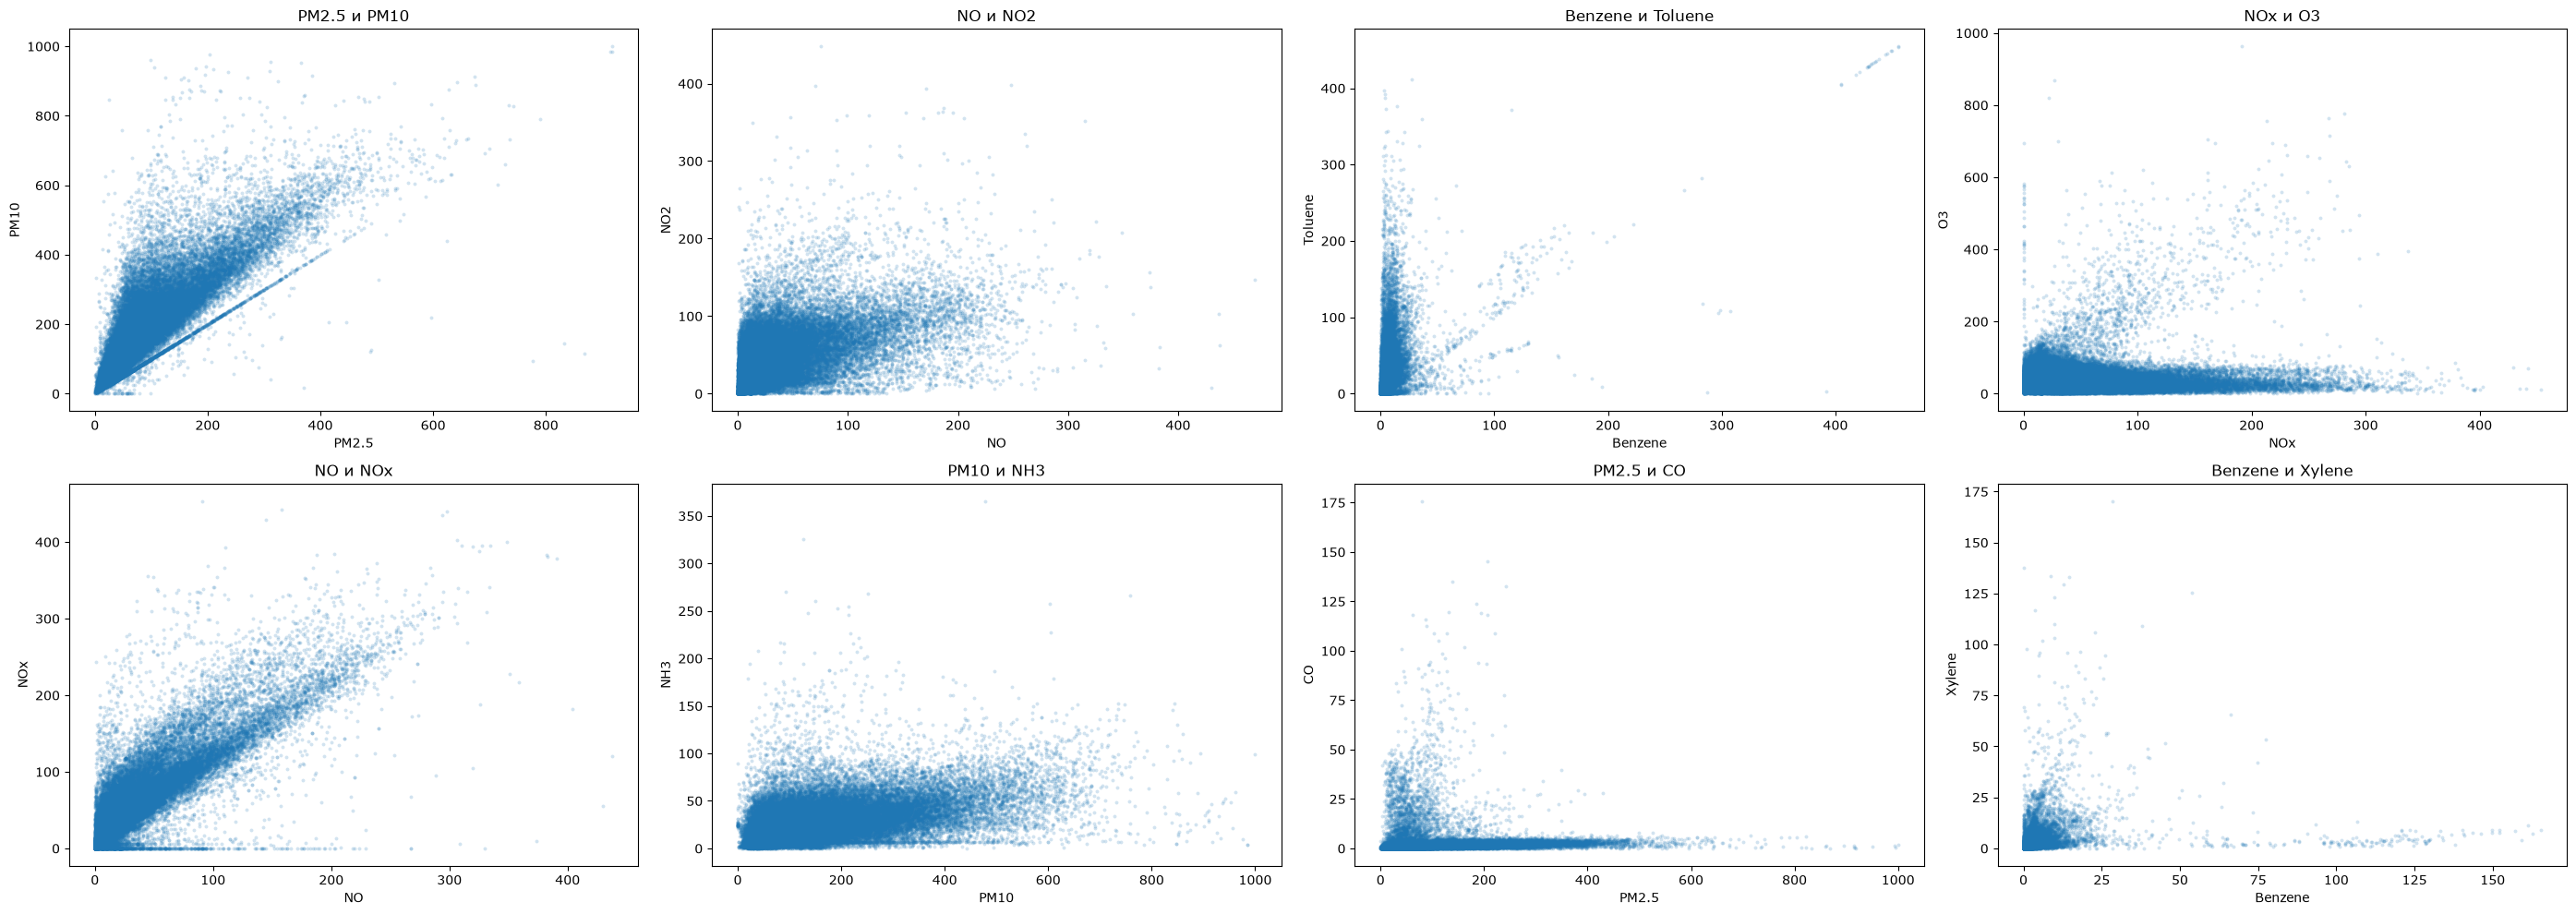

In [87]:
pairs = [
    ("PM2.5", "PM10"),
    ("NO", "NO2"),
    ("Benzene", "Toluene"),
    ("NOx", "O3"),
    ("NO", "NOx"),
    ("PM10", "NH3"),
    ("PM2.5", "CO"),
    ("Benzene", "Xylene")
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(28, 10)
)

for (x, y), ax in zip(pairs, axes.flat):
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        ax=ax,
        s=8,
        alpha=0.2,
        linewidth=0
    )

    ax.set_title(f"{x} и {y}")

plt.tight_layout()
plt.show()

In [14]:
df.count()

StationId      108035
Date           108035
PM2.5           86410
PM10            65329
NO              90929
NO2             91488
NOx             92535
NH3             59930
CO              95037
SO2             82831
O3              82467
Benzene         76580
Toluene         69333
Xylene          22898
AQI             87025
AQI_Bucket      87025
City           108035
State          108035
StationName    108035
dtype: int64

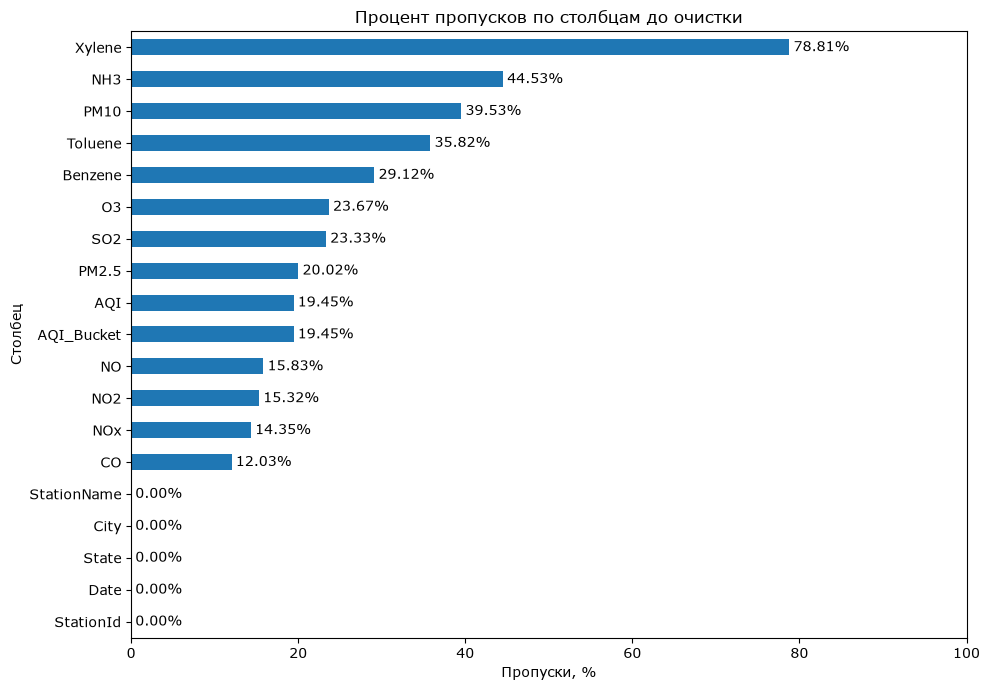

In [15]:
missing_percent = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values()
)
ax = missing_percent.plot(
    kind="barh",
    figsize=(10, 7)
)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.title("Процент пропусков по столбцам до очистки")
plt.xlabel("Пропуски, %")
plt.ylabel("Столбец")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

В признаке Xylene отсутствует 78,81% значений. При сохранении всех 12 входных признаков удаление строк с пропусками в признаках и целевых переменных оставляет 10 314 наблюдений. Исключение Xylene позволяет сохранить 35 732 наблюдения и увеличить количество представленных станций с 20 до 58.

Поэтому принято решение исключить Xylene из дальнейшего набора входных признаков. После исключения остаются 11 признаков, что соответствует требованию задания. Такое решение сохраняет больше наблюдений, однако приводит к потере информации об одном показателе загрязнения. Влияние очистки на распределения классов и географический состав выборки проверяется отдельно.

In [16]:
model_features = [
    feature for feature in features
    if feature != "Xylene"
]

In [17]:
df = df.drop(["Xylene"], axis=1)
df.head(5)

,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Bucket,City,State,StationName
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,NaN,NaN,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,184.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,197.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,198.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,188.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"


In [18]:
df.shape

(108035, 18)

In [19]:
duplicate_rows_df = df[df.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (0, 18)


In [20]:
df.count()

StationId      108035
Date           108035
PM2.5           86410
PM10            65329
NO              90929
NO2             91488
NOx             92535
NH3             59930
CO              95037
SO2             82831
O3              82467
Benzene         76580
Toluene         69333
AQI             87025
AQI_Bucket      87025
City           108035
State          108035
StationName    108035
dtype: int64

In [21]:
df = df.drop_duplicates()
df.count()

StationId      108035
Date           108035
PM2.5           86410
PM10            65329
NO              90929
NO2             91488
NOx             92535
NH3             59930
CO              95037
SO2             82831
O3              82467
Benzene         76580
Toluene         69333
AQI             87025
AQI_Bucket      87025
City           108035
State          108035
StationName    108035
dtype: int64

In [22]:
df.isnull().sum()

StationId          0
Date               0
PM2.5          21625
PM10           42706
NO             17106
NO2            16547
NOx            15500
NH3            48105
CO             12998
SO2            25204
O3             25568
Benzene        31455
Toluene        38702
AQI            21010
AQI_Bucket     21010
City               0
State              0
StationName        0
dtype: int64

In [23]:
df = df.dropna()  # Dropping the missing values.
df.count()

StationId      35732
Date           35732
PM2.5          35732
PM10           35732
NO             35732
NO2            35732
NOx            35732
NH3            35732
CO             35732
SO2            35732
O3             35732
Benzene        35732
Toluene        35732
AQI            35732
AQI_Bucket     35732
City           35732
State          35732
StationName    35732
dtype: int64

In [24]:
df.isnull().sum()  # After dropping the values

StationId      0
Date           0
PM2.5          0
PM10           0
NO             0
NO2            0
NOx            0
NH3            0
CO             0
SO2            0
O3             0
Benzene        0
Toluene        0
AQI            0
AQI_Bucket     0
City           0
State          0
StationName    0
dtype: int64

In [25]:
# city_counts = (
#     df["City"]
#     .value_counts()
#     .sort_values()
# )

# city_counts.plot(
#     kind="barh",
#     figsize=(10, 12)
# )

# plt.title("Количество наблюдений по городам")
# plt.xlabel("Количество наблюдений (станция — день)")
# plt.ylabel("Город")

# plt.tight_layout()
# plt.show()

In [26]:
df.head(5)

,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Bucket,City,State,StationName
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,184.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,197.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,198.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,188.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"
5,AP001,2017-11-29,72.47,114.84,5.23,23.20,16.59,12.25,0.16,10.55,109.74,0.21,4.71,173.0,Moderate,Amaravati,Andhra Pradesh,"Secretariat, Amaravati - APPCB"


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
PM2.5,1.000000,0.860014,0.596928,0.564511,0.581345,0.535877,0.648186,0.324898,0.162193,0.140630,0.360556,0.892566
PM10,0.860014,1.000000,0.609275,0.555975,0.601552,0.515370,0.620082,0.367726,0.014743,0.127748,0.360946,0.898689
NO,0.596928,0.609275,1.000000,0.649915,0.875179,0.418732,0.657289,0.292112,0.035991,0.188086,0.351698,0.594750
NO2,0.564511,0.555975,0.649915,1.000000,0.766479,0.405553,0.564116,0.367662,0.254921,0.120599,0.277673,0.593155
NOx,0.581345,0.601552,0.875179,0.766479,1.000000,0.441087,0.621994,0.329895,0.129043,0.182746,0.286301,0.620568
NH3,0.535877,0.515370,0.418732,0.405553,0.441087,1.000000,0.445365,0.256584,0.134590,0.044502,0.220775,0.558208
CO,0.648186,0.620082,0.657289,0.564116,0.621994,0.445365,1.000000,0.346630,0.126464,0.125819,0.353045,0.644343
SO2,0.324898,0.367726,0.292112,0.367662,0.329895,0.256584,0.346630,1.000000,0.188818,0.048465,0.209112,0.376059
O3,0.162193,0.014743,0.035991,0.254921,0.129043,0.134590,0.126464,0.188818,1.000000,-0.011131,0.048421,0.213957
Benzene,0.140630,0.127748,0.188086,0.120599,0.182746,0.044502,0.125819,0.048465,-0.011131,1.000000,0.509323,0.129473


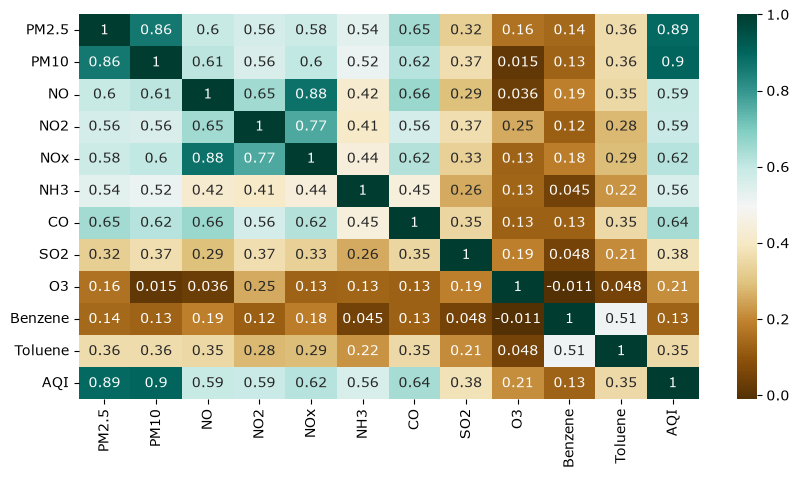

In [27]:
plt.figure(figsize=(10,5))
c = df.corr(numeric_only=True)
sns.heatmap(c,cmap="BrBG",annot=True)
c

In [28]:
X = df[model_features]   # 11 показателей загрязнения
y = df["AQI_Bucket"]     # Правильные категории качества воздуха

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая часть:", X_train.shape)
print("Тестовая часть:", X_test.shape)

Обучающая часть: (28585, 11)
Тестовая часть: (7147, 11)


In [29]:
print("До разделения:", len(y))
print("Обучающая часть:", len(y_train))
print("Тестовая часть:", len(y_test))
print("Сумма частей:", len(y_train) + len(y_test))

До разделения: 35732
Обучающая часть: 28585
Тестовая часть: 7147
Сумма частей: 35732


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
class_counts = y_train.value_counts()

target_count = class_counts.max()

balance_plan = pd.DataFrame({
    "Сейчас строк": class_counts,
    "Нужно сгенерировать": target_count - class_counts
})

balance_plan

,Сейчас строк,Нужно сгенерировать
AQI_Bucket,,
Moderate,10351,0
Satisfactory,6717,3634
Very Poor,3937,6414
Poor,3914,6437
Severe,2016,8335
Good,1650,8701


In [32]:
X_train_balanced, y_train_balanced = generate_balanced_data(
    X_train_scaled,
    y_train,
    k_neighbors=5,
    random_state=42
)

In [33]:
print("До генерации:", X_train_scaled.shape)
print("После генерации:", X_train_balanced.shape)

pd.Series(y_train_balanced).value_counts()

До генерации: (28585, 11)
После генерации: (62106, 11)


Moderate        10351
Very Poor       10351
Satisfactory    10351
Severe          10351
Poor            10351
Good            10351
Name: count, dtype: int64

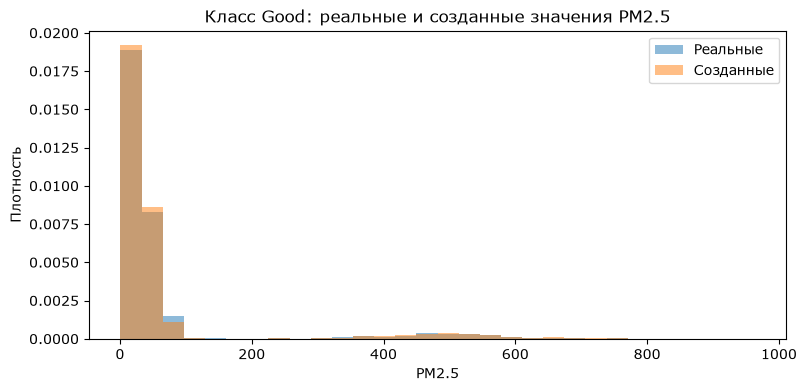

In [34]:
# Проверка(сравнение распределений реальных и созданных данных)
# В результате генератора сначала идут реальные строки,
# затем созданные. Отделяем созданные строки.
n_real = len(X_train_scaled)

X_synthetic = scaler.inverse_transform(
    X_train_balanced[n_real:]
)
y_synthetic = y_train_balanced[n_real:]

# Берём O3 только для класса Good.
real = X_train.loc[y_train == "Severe", "O3"]

feature_index = model_features.index("O3")
generated = X_synthetic[
    y_synthetic == "Severe", feature_index
]

# Одинаковые интервалы для обеих гистограмм.
bins = np.histogram_bin_edges(
    np.concatenate([real, generated]), bins=30
)

plt.figure(figsize=(9, 4))
plt.hist(real, bins=bins, density=True, alpha=0.5, label="Реальные")
plt.hist(generated, bins=bins, density=True, alpha=0.5, label="Созданные")
plt.xlabel("PM2.5")
plt.ylabel("Плотность")
plt.title("Класс Good: реальные и созданные значения PM2.5")
plt.legend()
plt.show()

In [49]:
def create_pipeline(model):
    return Pipeline([
        ("scaler", StandardScaler()),

        ("generator", FunctionSampler(
            func=generate_balanced_data,
            kw_args={
                "k_neighbors": 5,
                "random_state": 42
            }
        )),

        ("model", model)
    ])

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [ ]:
knn_pipeline = create_pipeline(KNeighborsClassifier())

param_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 11, 17],
    "model__weights": ["uniform", "distance"]
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

knn_search.fit(X_train, y_train)
best_knn_pipeline = knn_search.best_estimator_

print("Лучшие параметры:", knn_search.best_params_)
print("Средний F1 на проверках:", knn_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Лучшие параметры: {'model__n_neighbors': 21, 'model__weights': 'distance'}
Средний F1 на проверках: 0.723018417201624


In [ ]:
svm_pipeline = create_pipeline(SVC(kernel="rbf"))

svm_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", "auto"]
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=cv,                   
    n_jobs=-1,
    verbose=1
)

svm_search.fit(X_train, y_train)

best_svm_pipeline = svm_search.best_estimator_

print("Лучшие параметры SVM:", svm_search.best_params_)
print("Средний F1 на проверках:", svm_search.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Лучшие параметры SVM: {'model__C': 10, 'model__gamma': 'scale'}
Средний F1 на проверках: 0.7653630972090538


In [ ]:
rf_pipeline = create_pipeline(
    RandomForestClassifier(random_state=42)
)

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None]
    # 'min_samples_split': [4, 6, 8]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf_pipeline = rf_search.best_estimator_

print("Лучшие параметры Random Forest:", rf_search.best_params_)
print("Средний F1 на проверках:", rf_search.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Лучшие параметры Random Forest: {'model__max_depth': 20, 'model__n_estimators': 200}
Средний F1 на проверках: 0.7904753739614043


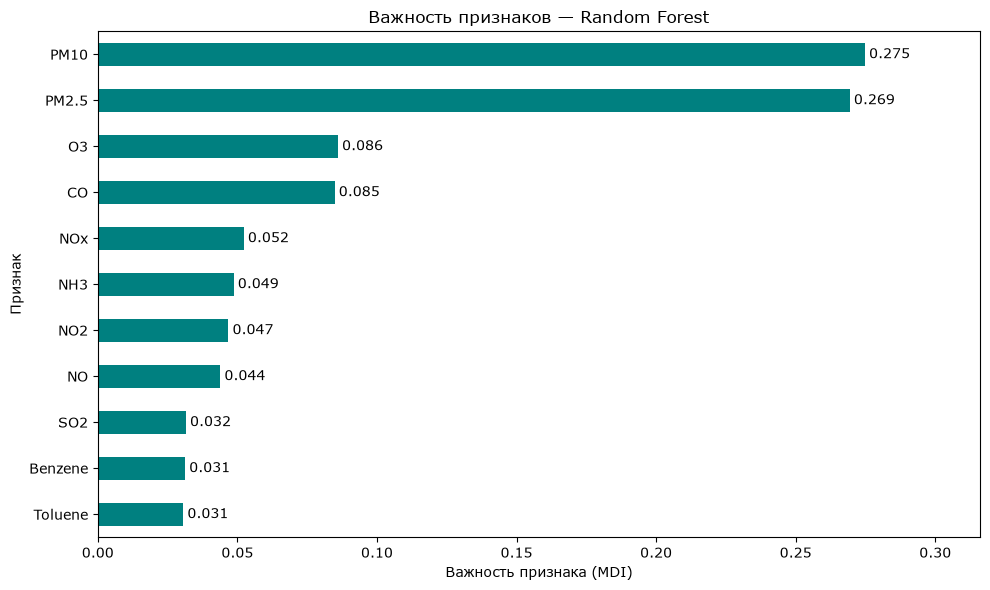

In [73]:
rf_model = best_rf_pipeline.named_steps["model"]
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

feature_importance.plot.barh(
    ax=ax,
    color="teal"
)

ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.margins(x=0.15)

ax.set_title("Важность признаков — Random Forest")
ax.set_xlabel("Важность признака (MDI)")
ax.set_ylabel("Признак")
fig.tight_layout()
plt.show()

In [79]:
joblib.dump(best_knn_pipeline.named_steps["model"], 'knn_model.pkl')

['knn_model.pkl']

In [80]:
joblib.dump(best_svm_pipeline.named_steps["model"], 'svm_model.pkl')

['svm_model.pkl']

In [81]:
joblib.dump(best_rf_pipeline.named_steps["model"], 'rf_model.pkl')

['rf_model.pkl']

In [88]:
import numpy as np
from sklearn.metrics import roc_auc_score


def calculate_macro_roc_auc(pipeline, X_test, y_test):
    if hasattr(pipeline, "predict_proba"):
        scores = pipeline.predict_proba(X_test)
    else:
        scores = pipeline.decision_function(X_test)

    auc_per_class = []

    for i, class_name in enumerate(pipeline.classes_):
        # Текущий класс — 1, остальные — 0.
        y_binary = (y_test == class_name).astype(int)

        class_auc = roc_auc_score(y_binary, scores[:, i])
        auc_per_class.append(class_auc)

    # Одинаковый вес каждого класса — усреднение macro.
    return float(np.mean(auc_per_class))

In [89]:
y_pred_knn = best_knn_pipeline.predict(X_test)

print(classification_report(
    y_test,
    y_pred_knn,
    digits=3,
    zero_division=0
))
roc_auc_knn = calculate_macro_roc_auc(
    best_knn_pipeline, X_test, y_test
)
print(f"ROC-AUC KNN (OvR, macro):           {roc_auc_knn:.3f}")

              precision    recall  f1-score   support

        Good      0.623     0.903     0.737       412
    Moderate      0.862     0.685     0.763      2588
        Poor      0.573     0.723     0.639       979
Satisfactory      0.734     0.776     0.754      1679
      Severe      0.726     0.827     0.774       504
   Very Poor      0.735     0.678     0.705       985

    accuracy                          0.733      7147
   macro avg      0.709     0.765     0.729      7147
weighted avg      0.751     0.733     0.735      7147

ROC-AUC KNN (OvR, macro):           0.947


In [90]:
y_pred_svm = best_svm_pipeline.predict(X_test)

print(classification_report(
    y_test,
    y_pred_svm,
    digits=3,
    zero_division=0
))
roc_auc_svm = calculate_macro_roc_auc(
    best_svm_pipeline, X_test, y_test
)
print(f"ROC-AUC SVM (OvR, macro):           {roc_auc_svm:.3f}")

              precision    recall  f1-score   support

        Good      0.671     0.913     0.774       412
    Moderate      0.878     0.767     0.819      2588
        Poor      0.639     0.761     0.695       979
Satisfactory      0.790     0.791     0.790      1679
      Severe      0.779     0.837     0.807       504
   Very Poor      0.785     0.747     0.766       985

    accuracy                          0.783      7147
   macro avg      0.757     0.803     0.775      7147
weighted avg      0.793     0.783     0.785      7147

ROC-AUC SVM (OvR, macro):           0.959


In [91]:
y_pred_rf = best_rf_pipeline.predict(X_test)

print(classification_report(
    y_test,
    y_pred_rf,
    digits=3,
    zero_division=0
))
roc_auc_rf = calculate_macro_roc_auc(
    best_rf_pipeline, X_test, y_test
)
print(f"ROC-AUC RF (OvR, macro):           {roc_auc_rf:.3f}")

              precision    recall  f1-score   support

        Good      0.754     0.842     0.796       412
    Moderate      0.867     0.802     0.833      2588
        Poor      0.659     0.744     0.699       979
Satisfactory      0.809     0.817     0.813      1679
      Severe      0.793     0.853     0.822       504
   Very Poor      0.792     0.763     0.777       985

    accuracy                          0.798      7147
   macro avg      0.779     0.804     0.790      7147
weighted avg      0.803     0.798     0.799      7147

ROC-AUC RF (OvR, macro):           0.970


In [62]:
class_order = [
    "Good", "Satisfactory", "Moderate",
    "Poor", "Very Poor", "Severe"
]


def plot_confusion_matrix(y_true, y_pred, model_name):
    # Каждый вызов создаёт отдельный рисунок.
    fig, ax = plt.subplots(figsize=(10, 8))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=class_order,
        cmap="GnBu",
        values_format="d",      # Показываем количество наблюдений.
        xticks_rotation=30,
        ax=ax
    )

    ax.set_title(f"Матрица ошибок — {model_name}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Настоящий класс")

    fig.tight_layout()
    plt.show()

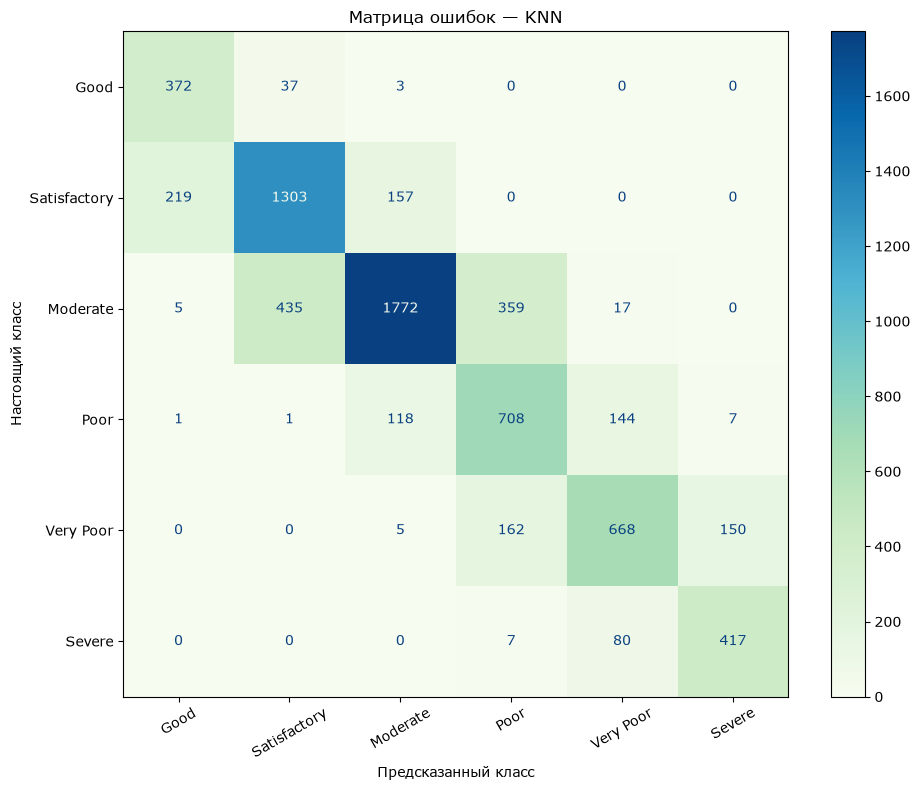

In [63]:
plot_confusion_matrix(y_test, y_pred_knn, "KNN")

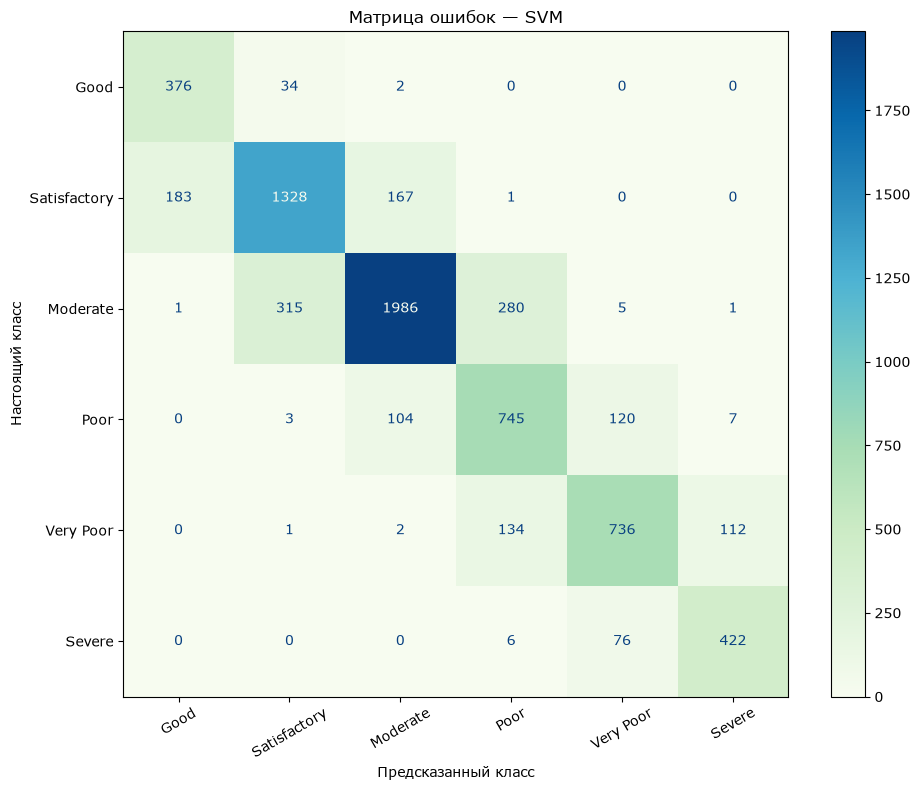

In [74]:
plot_confusion_matrix(y_test, y_pred_svm, "SVM")

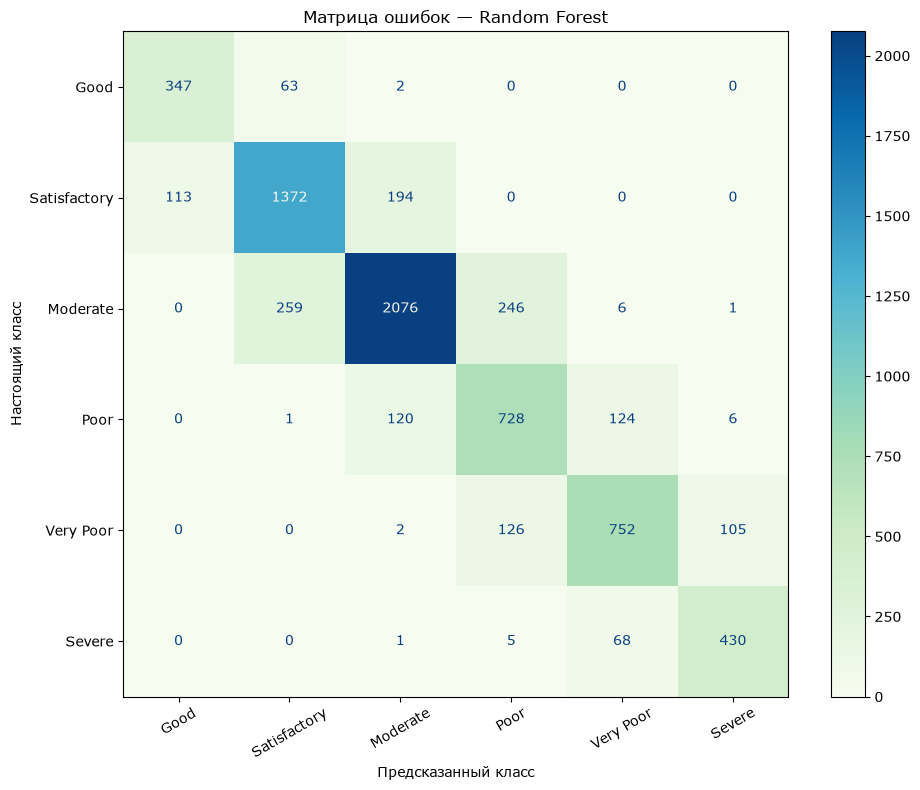

In [65]:
plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")